# Sub-unit hazard from nested, mixed-resolution reports

Events happen at points, but the record names only the GADM unit they were reported in, and that unit is sometimes a second-level division (ADM2), sometimes a first-level division (ADM1) and sometimes the whole country (ADM0). The units nest: every ADM2 lies in one ADM1 and every ADM1 in one ADM0. The question is whether the hazard inside a unit can be recovered from such a record, and how much each resolution of report contributes.

The answer rests on one likelihood. If an event's reporting level does not depend on where inside its country it fell, the events reported at unit $A$ are a Poisson process thinned to $A$, and

$$\log L = \sum_{A} n_A \log \Lambda_A - \sum_i \lambda_i, \qquad \Lambda_A = \sum_{i \in A} \lambda_i,$$

where $i$ runs over the atoms of the lattice and $A$ over every unit at every level. The reporting probabilities factor out as constants. Here the rate is a known function of covariates that vary inside units, so sub-unit structure is identified only through their mix across units. Notebook 06 adds a spatial field the covariates do not explain.

In [1]:
import arviz as az
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import shapely

from nested_plotting import (
    LATTICE_EXTENT,
    POSTERIOR_COLOR,
    RATE_FLOOR,
    TRUTH_COLOR,
    draw_borders,
    draw_stack,
    floored_log10,
    plot_atoms,
    spread_over_units,
)

from climate_risk.models.aggregation import Aggregation
from climate_risk.plotting import configure_plot_style

configure_plot_style()

# One generator per stage, so rerunning a stage never moves the draws of another.
SEED = 20261020
GEOGRAPHY_SEED, COLOR_SEED, EVENT_SEED, REPORTING_SEED = SEED, SEED + 1, SEED + 3, SEED + 4

## The geography

A square lattice of atoms, grouped into ADM2 units, ADM2 into ADM1 and ADM1 into ADM0. Each level is a partition of the one below it, so an atom has exactly one ancestor at every level. Atoms are equal in area, which keeps the base measure out of the way.

In [2]:
GRID_SIDE = 30
N_ADM2, N_ADM1, N_ADM0 = 60, 12, 3
LLOYD_STEPS = 25
LEVELS = ("ADM2", "ADM1", "ADM0")

n_atoms = GRID_SIDE**2
column, row = (index.ravel() for index in np.meshgrid(np.arange(GRID_SIDE), np.arange(GRID_SIDE)))
atom_x, atom_y = (column + 0.5) / GRID_SIDE, (row + 0.5) / GRID_SIDE
atom_centroids = np.column_stack([atom_x, atom_y])

# Edges as k / GRID_SIDE, computed once per grid line, so neighbors share them exactly and a
# dissolve leaves no slivers between atoms.
edges = np.arange(GRID_SIDE + 1) / GRID_SIDE
atom_cells = gpd.GeoSeries(shapely.box(edges[column], edges[row], edges[column + 1], edges[row + 1]))

In [3]:
def group_into(centroids, n_groups, *, weights, rng):
    """Assign each child to one of ``n_groups`` compact parents, by weighted Lloyd iteration."""
    seeds = centroids[rng.choice(len(centroids), size=n_groups, replace=False)]
    for _ in range(LLOYD_STEPS):
        parent = np.argmin(((centroids[:, None, :] - seeds[None, :, :]) ** 2).sum(axis=-1), axis=1)
        seeds = np.array(
            [np.average(centroids[parent == group], axis=0, weights=weights[parent == group]) for group in range(n_groups)]
        )

    return parent, seeds


geography_rng = np.random.default_rng(GEOGRAPHY_SEED)
adm2_of_atom, adm2_centroids = group_into(atom_centroids,
                                          N_ADM2,
                                          weights=np.ones(n_atoms),
                                          rng=geography_rng)
adm1_of_adm2, adm1_centroids = group_into(adm2_centroids,
                                          N_ADM1,
                                          weights=np.bincount(adm2_of_atom),
                                          rng=geography_rng)
adm0_of_adm1, _ = group_into(adm1_centroids,
                             N_ADM0,
                             weights=np.bincount(adm1_of_adm2[adm2_of_atom]),
                             rng=geography_rng)

unit_of_atom = {
    "ADM2": adm2_of_atom,
    "ADM1": adm1_of_adm2[adm2_of_atom],
    "ADM0": adm0_of_adm1[adm1_of_adm2[adm2_of_atom]],
}
borders = {
    level: gpd.GeoDataFrame({"unit": unit_of_atom[level]}, geometry=atom_cells).dissolve(by="unit").boundary
    for level in LEVELS
}

In [4]:
atoms_per_unit = {level: np.bincount(unit_of_atom[level]) for level in LEVELS}

pd.DataFrame(
    {
        "units": {level: len(counts) for level, counts in atoms_per_unit.items()},
        "atoms per unit, smallest": {level: counts.min() for level, counts in atoms_per_unit.items()},
        "atoms per unit, median": {level: np.median(counts) for level, counts in atoms_per_unit.items()},
        "atoms per unit, largest": {level: counts.max() for level, counts in atoms_per_unit.items()},
    }
)

,units,"atoms per unit, smallest","atoms per unit, median","atoms per unit, largest"
ADM2,60,8,15.00,27
ADM1,12,42,70.00,105
ADM0,3,225,257.00,418


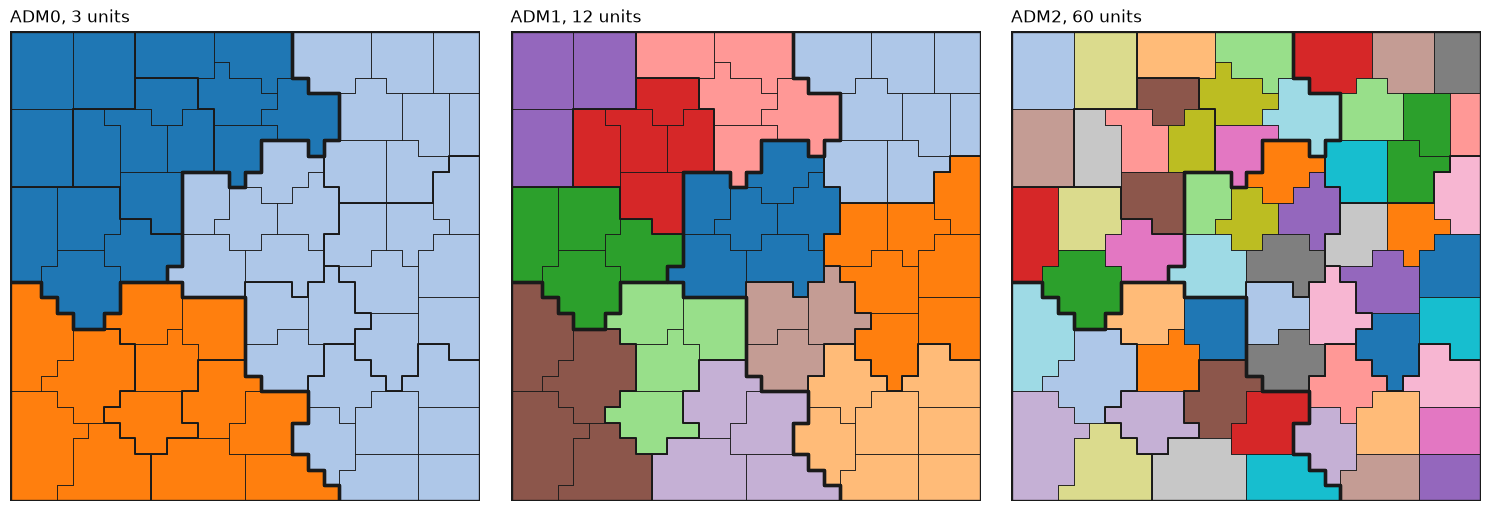

In [5]:
color_rng = np.random.default_rng(COLOR_SEED)

figure, axes = plt.subplots(1, len(LEVELS), figsize=(15, 5))

for axis, level in zip(axes, reversed(LEVELS), strict=True):
    count = unit_of_atom[level].max() + 1
    palette = plt.get_cmap("tab20")(color_rng.permutation(count) % 20)
    axis.imshow(palette[unit_of_atom[level]].reshape(GRID_SIDE, GRID_SIDE, 4),
                origin="lower",
                extent=LATTICE_EXTENT)
    draw_borders(axis, borders, color="0.1")

    axis.set_axis_off()
    axis.set_title(f"{level}, {count} units", loc="left")

plt.show()

Every unit is compact and every level nests in the one above. A median ADM2 holds 15 atoms and a median ADM0 holds 257, so a country-level report spreads an event over about 17 times as many atoms as an ADM2 report.

## The truth

Two covariates, distance to a river and elevation, both smooth in space and both varying inside every unit. The log rate is linear in them, with the intercept solved so the record carries 150 events, about 50 per country. That is the range EM-DAT geocodes to admin units in Southeast Asia, from 9 events in Timor-Leste and 26 in Laos to 387 in the Philippines. The share of each covariate's variance that lies inside units at each level is the part a report at that level cannot see.

In [6]:
TARGET_EVENTS = 150
TRUE_SLOPES = np.array([-0.8, 0.5])
COVARIATE_NAMES = ("distance to river", "elevation")


def standardized(values):
    """Centered and scaled to unit standard deviation."""
    return (values - values.mean()) / values.std()


river_x = 0.5 + 0.2 * np.sin(2.5 * np.pi * atom_y)
elevation = np.sin(3.0 * atom_x + 1.0) * np.cos(2.0 * atom_y) + 0.6 * atom_y
covariates = np.column_stack([standardized(np.abs(atom_x - river_x)), standardized(elevation)])

linear_part = covariates @ TRUE_SLOPES
TRUE_INTERCEPT = float(np.log(TARGET_EVENTS) - np.log(np.exp(linear_part).sum()))
true_log_rate = TRUE_INTERCEPT + linear_part
true_rate = np.exp(true_log_rate)

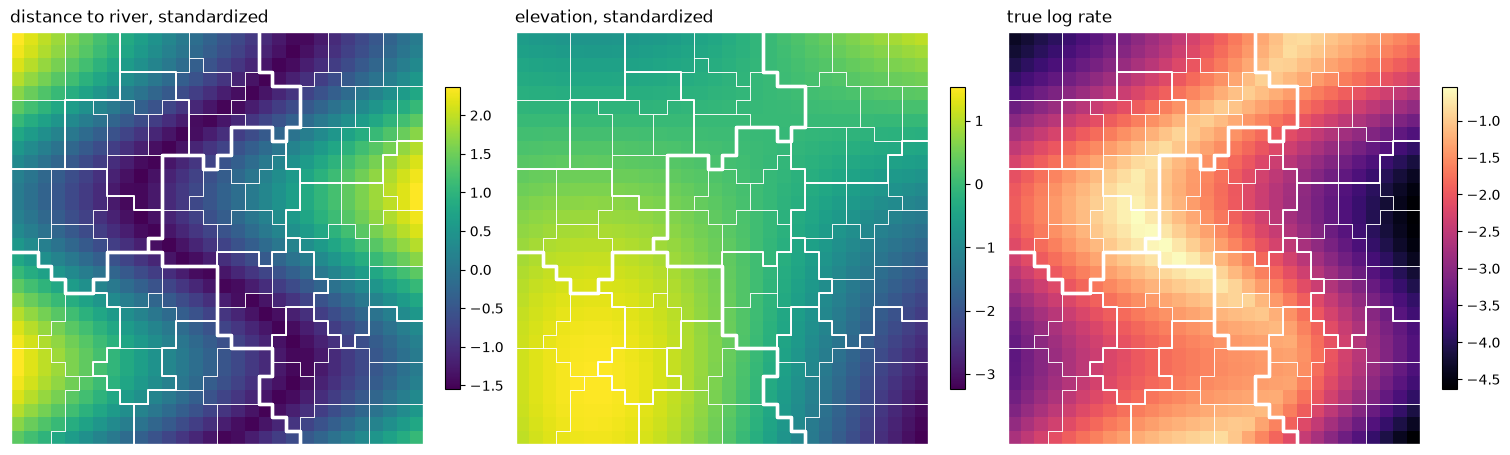

In [7]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4.6))

for axis, name, values in zip(axes[:2], COVARIATE_NAMES, covariates.T, strict=True):
    drawn = plot_atoms(axis,
                       values,
                       borders,
                       title=f"{name}, standardized",
                       cmap="viridis")
    figure.colorbar(drawn, ax=axis, shrink=0.7)

drawn = plot_atoms(axes[2], true_log_rate, borders, title="true log rate")
figure.colorbar(drawn, ax=axes[2], shrink=0.7)

plt.show()

In [8]:
def within_share(values, units):
    """Share of the variance of ``values`` that lies inside units, invisible to a report at that level."""
    unit_means = np.bincount(units, weights=values) / np.bincount(units)

    return float(((values - unit_means[units]) ** 2).sum() / ((values - values.mean()) ** 2).sum())


pd.DataFrame(
    {
        level: {name: within_share(values, unit_of_atom[level]) for name, values in zip(COVARIATE_NAMES, covariates.T)}
        for level in LEVELS
    }
).rename_axis("variance inside units").round(3)

,ADM2,ADM1,ADM0
variance inside units,,,
distance to river,0.10,0.44,0.96
elevation,0.03,0.17,0.57


In [21]:
def unit_means(values, units):
    """Mean of ``values`` over each unit."""
    return np.bincount(units, weights=values) / np.bincount(units)


pd.Series(
    {
        "atoms": float(np.corrcoef(covariates.T)[0, 1]),
        **{
            f"between {level} units": float(
                np.corrcoef(*(unit_means(values, unit_of_atom[level]) for values in covariates.T))[0, 1]
            )
            for level in LEVELS
        },
    },
    name="correlation of the two covariates",
).round(2).to_frame()

,correlation of the two covariates
atoms,0.01
between ADM2 units,-0.06
between ADM1 units,0.08
between ADM0 units,0.76


Inside ADM2 units the covariates keep 10% and 3% of their variance, so an ADM2 report loses almost nothing about either. Distance to river keeps 44% inside ADM1 units, because the river meanders at a scale finer than an ADM1, and 96% inside ADM0. Country totals therefore carry almost no contrast in distance to river.

The two covariates are uncorrelated across atoms and across ADM2 and ADM1 units, but their means over the three countries correlate at 0.76. An ADM0 record has three numbers to fit and two covariates that move together across them, so it cannot tell the two slopes apart.

## Events and how they are reported

Events are drawn once, at the atoms. Each regime then reports the same events differently, so any difference between fits is the price of the reporting and nothing else. The atom regime is the oracle: every event located exactly. In the mixed regime each event draws its level from one set of shares everywhere. In the per-country regime each country has its own habit: one reports mostly at ADM2, one mostly at ADM1, and one only as a whole country. In both, the level is drawn independently of where inside its country the event fell, which is the condition under which the thinned likelihood is exact.

Every unit at every level becomes one row of a single operator, with atoms as a fourth level. A record is then a count per row, and a regime is a choice of which rows its events land in.

In [9]:
ALL_LEVELS = ("atom", *LEVELS)

unit_of_atom["atom"] = np.arange(n_atoms)
n_units = {level: int(unit_of_atom[level].max()) + 1 for level in ALL_LEVELS}
first_row = dict(zip(ALL_LEVELS, np.cumsum([0, *(n_units[level] for level in ALL_LEVELS[:-1])]), strict=True))
rows_of = {level: slice(first_row[level], first_row[level] + n_units[level]) for level in ALL_LEVELS}

reporting = Aggregation(units=tuple(f"{level} {unit}" for level in ALL_LEVELS for unit in range(n_units[level])),
                        rows=np.concatenate([first_row[level] + unit_of_atom[level] for level in ALL_LEVELS]),
                        columns=np.tile(np.arange(n_atoms), len(ALL_LEVELS)),
                        weights=np.ones(n_atoms * len(ALL_LEVELS)),
                        n_cells=n_atoms)


def country_of_units(level):
    """The ADM0 each unit at ``level`` lies in."""
    countries = np.empty(n_units[level], dtype=int)
    countries[unit_of_atom[level]] = unit_of_atom["ADM0"]

    return countries


country_of_row = np.concatenate([country_of_units(level) for level in ALL_LEVELS])
level_of_row = np.repeat(np.arange(len(ALL_LEVELS)), [n_units[level] for level in ALL_LEVELS])


def reports_by_country(counts):
    """Events reported at each level in each country, shape ``(country, level)``."""
    table = np.zeros((N_ADM0, len(ALL_LEVELS)))
    np.add.at(table, (country_of_row, level_of_row), counts)

    return table

In [10]:
MIXED_SHARES = {"ADM2": 0.3, "ADM1": 0.4, "ADM0": 0.3}
COUNTRY_SHARES = ({"ADM2": 0.8, "ADM1": 0.2}, {"ADM1": 0.8, "ADM0": 0.2}, {"ADM0": 1.0})

event_rng = np.random.default_rng(EVENT_SEED)
event_atoms = np.repeat(np.arange(n_atoms), event_rng.poisson(true_rate))
n_events = len(event_atoms)

reporting_rng = np.random.default_rng(REPORTING_SEED)


def record(levels):
    """The count reported at each row of ``reporting``, given the level each event is reported at."""
    reported_rows = [
        first_row[level] + unit_of_atom[level][atom] for atom, level in zip(event_atoms, levels, strict=True)
    ]

    return np.bincount(reported_rows, minlength=reporting.n_units)


def country_level(country):
    """One reporting level drawn from ``country``'s own shares."""
    shares = COUNTRY_SHARES[country]

    return reporting_rng.choice(list(shares), p=list(shares.values()))


regimes = {level: record([level] * n_events) for level in ALL_LEVELS}
regimes["mixed"] = record(reporting_rng.choice(list(MIXED_SHARES),
                                               size=n_events,
                                               p=list(MIXED_SHARES.values())))
regimes["by country"] = record([country_level(country) for country in unit_of_atom["ADM0"][event_atoms]])

pd.DataFrame(
    {regime: {level: counts[rows_of[level]].sum() for level in ALL_LEVELS} for regime, counts in regimes.items()}
).rename_axis("events reported at")

,atom,ADM2,ADM1,ADM0,mixed,by country
events reported at,,,,,,
atom,164,0,0,0,0,0
ADM2,0,164,0,0,44,44
ADM1,0,0,164,0,68,63
ADM0,0,0,0,164,52,57


In [11]:
pd.DataFrame(reports_by_country(regimes["by country"]).astype(int),
             index=pd.Index([f"ADM0 {country}" for country in range(N_ADM0)], name="by country"),
             columns=ALL_LEVELS)

,atom,ADM2,ADM1,ADM0
by country,,,,
ADM0 0,0,44,8,0
ADM0 1,0,0,55,13
ADM0 2,0,0,0,44


The same 164 events appear in every column. The mixed and per-country records each keep 44 events at ADM2, but they differ in where those come from. The mixed record's ADM2 reports are spread over all three countries. The per-country record's all come from ADM0 0, and ADM0 2 contributes only its own total.

## The model, fitted under each regime

The rate is log-linear in the covariates, which is the truth's own form, so any failure is the reporting's and none of it is misspecification.

Every row of the operator is observed as its own Poisson count, at its country's share for its level times the unit's rate. Each level partitions each country and a country's shares sum to one, so the shares separate from the rate exactly: under a flat Dirichlet prior per country their posterior is Dirichlet(1 + that country's reports per level), and fixing them at the observed fractions leaves the rate's likelihood unchanged up to a constant. Shares that are the same in every country are the special case.

In [12]:
sample_kwargs = {
    "chains": 8,
    "cores": 8,
    "tune": 500,
    "draws": 250,
    "nuts_sampler": "nutpie",
    "random_seed": SEED,
}


def build_model(counts):
    """Log-linear rate at the atoms, with every unit at every level observed as its own Poisson count."""
    coords = {"covariate": COVARIATE_NAMES, "atom": np.arange(n_atoms), "row": reporting.units}

    by_country = reports_by_country(counts)
    observed_shares = by_country / by_country.sum(axis=1, keepdims=True)

    with pm.Model(coords=coords) as model:
        intercept = pm.Normal("intercept",
                              mu=0.0,
                              sigma=2.0)
        slopes = pm.Normal("slopes",
                           mu=0.0,
                           sigma=1.0,
                           dims="covariate")

        log_rate = pm.Deterministic("log_rate",
                                    intercept + pm.math.dot(covariates, slopes),
                                    dims="atom")

        unit_rate = reporting.aggregate_symbolic(pm.math.exp(log_rate))
        pm.Poisson("events",
                   mu=observed_shares[country_of_row, level_of_row] * unit_rate,
                   observed=counts,
                   dims="row")

    return model

In [13]:
fits = {}
for regime, counts in regimes.items():
    with build_model(counts):
        fits[regime] = pm.sample(**sample_kwargs)

NUTS[nutpie]: [intercept, slopes]


Output()

NUTS[nutpie]: [intercept, slopes]


Output()

NUTS[nutpie]: [intercept, slopes]


...

Output()

NUTS[nutpie]: [intercept, slopes]


Output()

NUTS[nutpie]: [intercept, slopes]


Output()

## What each regime recovers

The two slopes against their true values, then how well the posterior over every atom's log rate matches the truth.

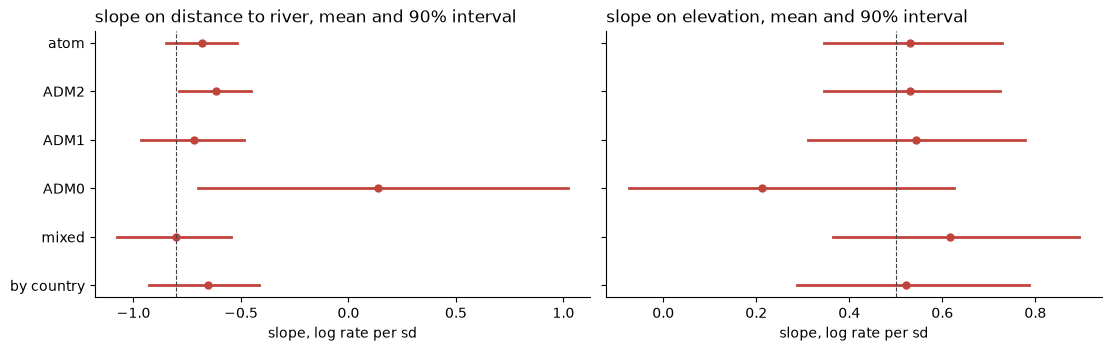

In [14]:
INTERVAL = 0.9
INTERVAL_BOUNDS = ((1 - INTERVAL) / 2, (1 + INTERVAL) / 2)

figure, axes = plt.subplots(1,
                            len(COVARIATE_NAMES),
                            figsize=(5.5 * len(COVARIATE_NAMES), 3.4),
                            sharey=True)

for axis, name, truth in zip(axes, COVARIATE_NAMES, TRUE_SLOPES, strict=True):
    for position, idata in enumerate(fits.values()):
        draws = idata.posterior["slopes"].sel(covariate=name)
        lower, upper = draws.quantile(INTERVAL_BOUNDS, dim=("chain", "draw")).to_numpy()
        axis.plot([lower, upper],
                  [position, position],
                  color=POSTERIOR_COLOR,
                  linewidth=2.0)
        axis.plot(float(draws.mean()),
                  position,
                  "o",
                  color=POSTERIOR_COLOR,
                  markersize=5)
    axis.axvline(truth,
                 color=TRUTH_COLOR,
                 linestyle="--",
                 linewidth=0.8)
    axis.set_xlabel("slope, log rate per sd")
    axis.set_title(f"slope on {name}, mean and {INTERVAL:.0%} interval", loc="left")

axes[0].set_yticks(range(len(fits)), list(fits))
axes[0].invert_yaxis()
plt.show()

Every regime but ADM0 puts both slopes near the truth, and the intervals widen as reporting coarsens. ADM2's river interval (-0.79 to -0.45) misses -0.8 by 0.01. The oracle's own mean is -0.68, so the miss comes from this draw of events. ADM0 is the failure. Its river slope has the wrong sign, +0.14, with an interval from -0.70 to 1.02 that excludes the truth, and its elevation slope falls to 0.21. Three counts for three parameters leave the record unable to separate the two slopes, since the covariates' country means move together (0.76).

In [15]:
def atom_summary(idata):
    """How well the posterior over the atom log rates matches the truth."""
    log_rate = idata.posterior["log_rate"]
    lower, upper = log_rate.quantile(INTERVAL_BOUNDS, dim=("chain", "draw")).to_numpy()
    error = log_rate.mean(dim=("chain", "draw")).to_numpy() - true_log_rate
    slope_sd = idata.posterior["slopes"].std(dim=("chain", "draw"))

    return {
        **{f"sd, slope on {name}": float(slope_sd.sel(covariate=name)) for name in COVARIATE_NAMES},
        "atom log rate, rmse": float(np.sqrt((error**2).mean())),
        f"atom log rate, {INTERVAL:.0%} coverage": float(((true_log_rate >= lower) & (true_log_rate <= upper)).mean()),
        "atom log rate, interval width": float((upper - lower).mean()),
        "largest r_hat": float(az.summary(idata, var_names=["intercept", "slopes"])["r_hat"].max()),
        "divergences": int(idata.sample_stats["diverging"].sum()),
    }


pd.DataFrame({regime: atom_summary(idata) for regime, idata in fits.items()}).round(3)

,atom,ADM2,ADM1,ADM0,mixed,by country
"sd, slope on distance to river",0.10,0.10,0.15,0.52,0.16,0.16
"sd, slope on elevation",0.12,0.11,0.14,0.22,0.16,0.15
"atom log rate, rmse",0.18,0.26,0.14,1.01,0.12,0.21
"atom log rate, 90% coverage",1.00,0.67,1.00,0.66,1.00,1.00
"atom log rate, interval width",0.56,0.54,0.70,1.76,0.77,0.74
largest r_hat,1.01,1.01,1.02,1.08,1.00,1.01
divergences,0.00,0.00,0.00,4.00,0.00,0.00


The slope sds rank the regimes. ADM2 matches the oracle (0.10 and 0.11 against 0.10 and 0.12). ADM1 and the two multi-level records are about half again wider on distance to river and a quarter wider on elevation. ADM0 is five times wider on distance to river and twice as wide on elevation.

Coverage across atoms is not 900 independent checks. Every atom's log rate is a function of the same three parameters, so a regime's coverage is close to all or nothing. ADM2 covers 67% because its river slope sits 1.8 posterior sd from the truth in this draw. ADM0 covers 66% for the larger reason above. The four divergences and r_hat of 1.08 in the ADM0 fit come from the same weak identification. Every other fit is clean.

### What the record shows against what the fit infers

The top row is the record as a reader without a model would map it: each event spread evenly over the unit it was reported in. A record reported at more than one level is drawn as a stack, one sheet per level over their sum, because spread onto a single sheet its levels blur together. The middle row is the posterior mean rate at each atom, and the bottom row is that mean against the truth. The first column is the truth itself: where the events actually fell, the rate they were drawn from, and the residual of the oracle fit. The top two rows share one log scale in events per atom.

In [16]:
def spread_at(counts, level):
    """The events reported at ``level``, each divided equally among the atoms of its unit."""
    return spread_over_units(counts[rows_of[level]], unit_of_atom[level])


def spread_evenly(counts):
    """Each reported event divided equally among the atoms of the unit it was reported in."""
    return sum(spread_at(counts, level) for level in ALL_LEVELS)


def record_layers(counts):
    """A record as one sheet per reporting level, coarsest first, then their sum."""
    layers = [
        (f"{level}, {counts[rows_of[level]].sum()} events", spread_at(counts, level), (level,))
        for level in reversed(LEVELS)
    ]

    return [*layers, ("sum", spread_evenly(counts), LEVELS)]


def posterior_rate(idata):
    """Posterior mean of the expected events at each atom."""
    return np.exp(idata.posterior["log_rate"]).mean(dim=("chain", "draw")).to_numpy()

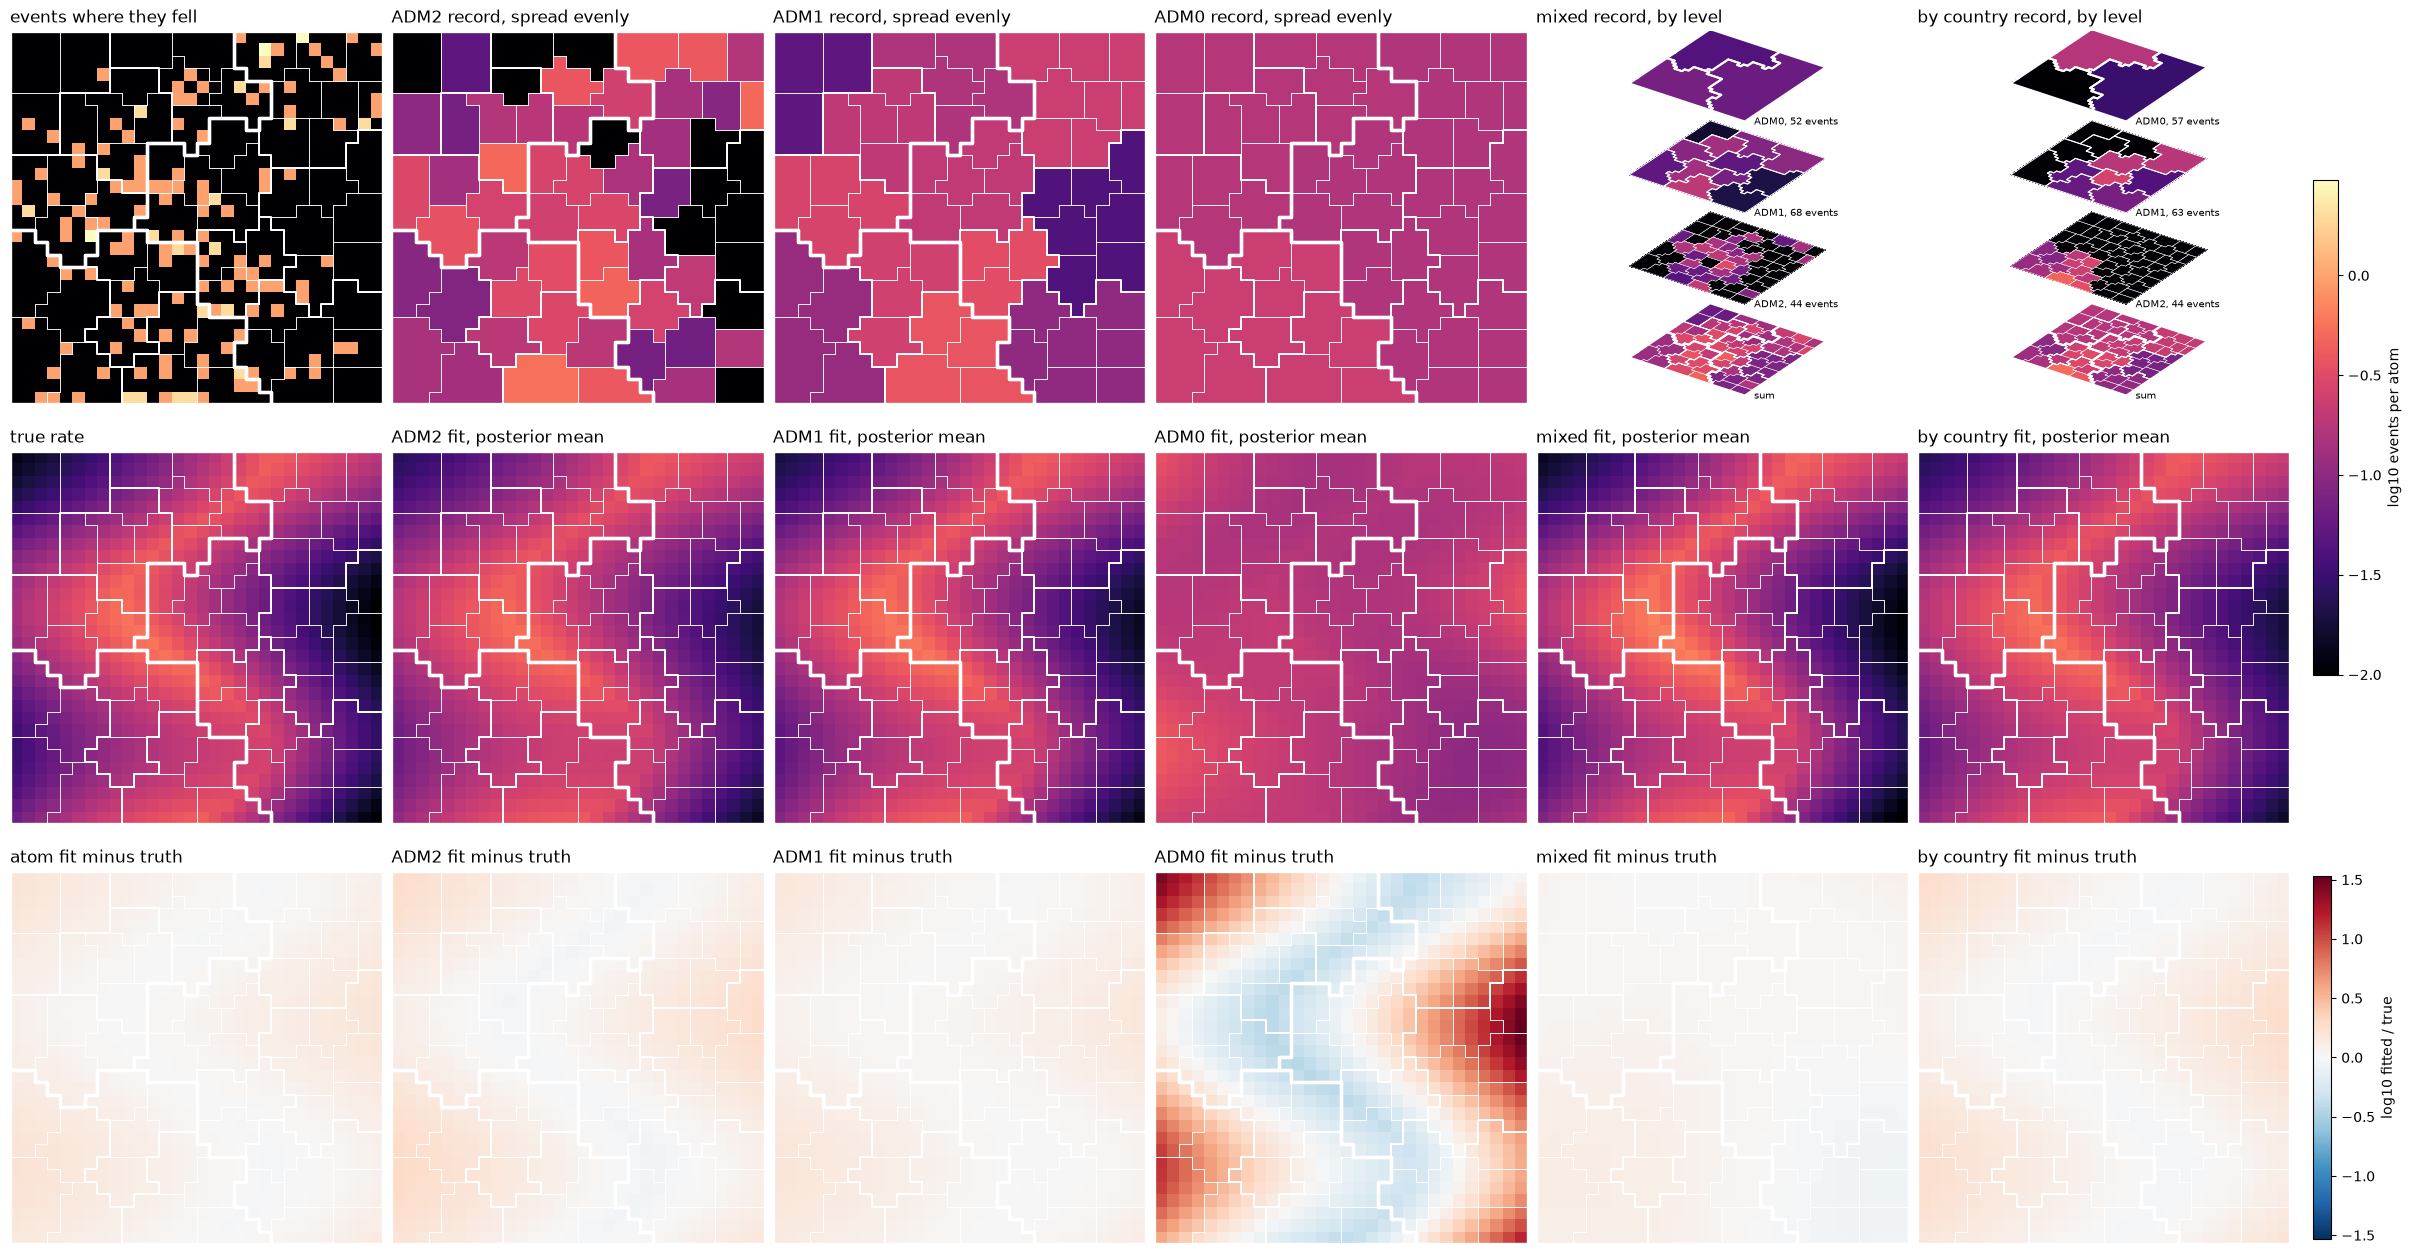

In [17]:
SHOWN_REGIMES = ("ADM2", "ADM1", "ADM0", "mixed", "by country")
STACKED_REGIMES = ("mixed", "by country")

columns = {"truth": (spread_evenly(regimes["atom"]), true_rate)}
columns |= {regime: (spread_evenly(regimes[regime]), posterior_rate(fits[regime])) for regime in SHOWN_REGIMES}

# The truth column has no fit of its own, so its residual is the oracle's: what the draw of events
# alone costs, before any reporting.
residuals = {
    name: np.log10(posterior_rate(fits["atom" if name == "truth" else name])) - np.log10(true_rate) for name in columns
}

low = np.log10(RATE_FLOOR)
high = np.log10(max(values.max() for pair in columns.values() for values in pair))
residual_limit = max(np.abs(residual).max() for residual in residuals.values())

figure, axes = plt.subplots(3, len(columns), figsize=(4.0 * len(columns), 12.6))
rate_axes = list(axes[:2].ravel())

for (name, (seen, inferred)), (top, middle, bottom) in zip(columns.items(), axes.T, strict=True):
    inferred_title = "true rate" if name == "truth" else f"{name} fit, posterior mean"
    residual_title = "atom fit minus truth" if name == "truth" else f"{name} fit minus truth"

    if name in STACKED_REGIMES:
        rate_axes.remove(top)
        top.remove()
        stack = figure.add_subplot(top.get_subplotspec(), projection="3d", proj_type="ortho")
        draw_stack(stack,
                   record_layers(regimes[name]),
                   borders,
                   vmin=low,
                   vmax=high,
                   label_size=7,
                   zoom=1.1,
                   line_scale=0.6)
        stack.set_title(f"{name} record, by level", loc="left")
    else:
        seen_title = "events where they fell" if name == "truth" else f"{name} record, spread evenly"
        plot_atoms(top,
                   floored_log10(seen),
                   borders,
                   title=seen_title,
                   vmin=low,
                   vmax=high)

    rate_drawn = plot_atoms(middle,
                            floored_log10(inferred),
                            borders,
                            title=inferred_title,
                            vmin=low,
                            vmax=high)
    residual_drawn = plot_atoms(bottom,
                                residuals[name],
                                borders,
                                title=residual_title,
                                cmap="RdBu_r",
                                vmin=-residual_limit,
                                vmax=residual_limit)

figure.colorbar(rate_drawn,
                ax=rate_axes,
                shrink=0.6,
                pad=0.01,
                label="log10 events per atom")
figure.colorbar(residual_drawn,
                ax=axes[2],
                shrink=0.9,
                pad=0.01,
                label="log10 fitted / true")
plt.show()

In [18]:
pd.DataFrame(
    {
        "rmse": {name: float(np.sqrt((residual**2).mean())) for name, residual in residuals.items()},
        "largest": {name: float(np.abs(residual).max()) for name, residual in residuals.items()},
    }
).rename(index={"truth": "atom"}).rename_axis("log10 residual").round(3)

,rmse,largest
log10 residual,,
atom,0.09,0.22
ADM2,0.12,0.30
ADM1,0.08,0.19
ADM0,0.47,1.53
mixed,0.05,0.12
by country,0.11,0.28


The record loses detail level by level. The ADM2 record still traces the river corridor and the empty pockets in the east, the ADM1 record keeps a broad west to east gradient, and the ADM0 record is three nearly flat blocks. In the stacks, the location information sits on the ADM2 sheet, and the coarser sheets add a smooth floor.

The fits rebuild the corridor inside every unit, because the covariates carry it. For the oracle, ADM2, ADM1, mixed and per-country fits, the residual stays within a factor of two (0.30 in log10) at every atom. The ADM0 residual is a river-shaped band reaching 1.5 in log10, the map of its wrong-signed river slope.

### Each part of the log rate against the truth

The level and each covariate term, posterior mean against the truth at every atom. A covariate term is a straight line through the origin, so its whole error is the slope's.

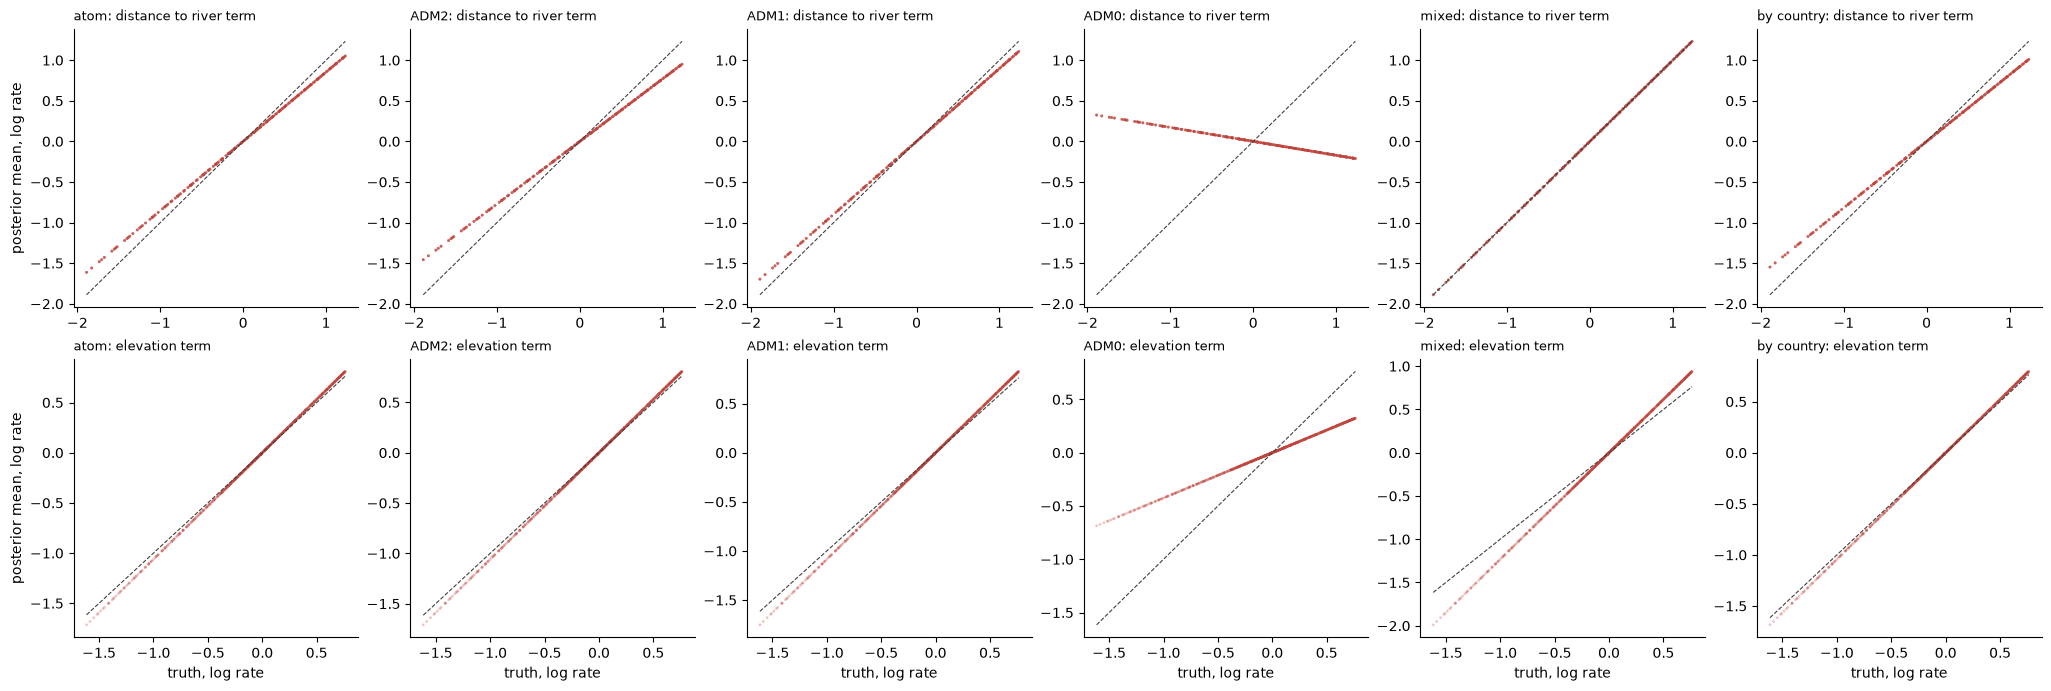

In [19]:
def covariate_terms_of(slopes):
    """Each covariate's contribution to the log rate at every atom."""
    return {
        f"{name} term": slope * values
        for name, slope, values in zip(COVARIATE_NAMES, slopes, covariates.T, strict=True)
    }


true_components = {"level": TRUE_INTERCEPT, **covariate_terms_of(TRUE_SLOPES)}
fitted_components = {
    regime: {
        "level": float(idata.posterior["intercept"].mean()),
        **covariate_terms_of(idata.posterior["slopes"].mean(dim=("chain", "draw")).to_numpy()),
    }
    for regime, idata in fits.items()
}
covariate_terms = [name for name in true_components if name != "level"]

figure, axes = plt.subplots(len(covariate_terms),
                            len(fits),
                            figsize=(3.4 * len(fits), 3.4 * len(covariate_terms)))

for row, name in zip(axes, covariate_terms, strict=True):
    truth = true_components[name]
    span = [truth.min(), truth.max()]
    for axis, (regime, fitted) in zip(row, fitted_components.items(), strict=True):
        axis.scatter(truth,
                     fitted[name],
                     s=4,
                     alpha=0.3,
                     color=POSTERIOR_COLOR,
                     edgecolor="none")
        axis.plot(span,
                  span,
                  color=TRUTH_COLOR,
                  linewidth=0.8,
                  linestyle="--")
        axis.set_title(f"{regime}: {name}", loc="left", fontsize=9)
    row[0].set_ylabel("posterior mean, log rate")

for axis in axes[-1]:
    axis.set_xlabel("truth, log rate")

plt.show()

In [20]:
pd.DataFrame(
    {
        regime: {
            "level, error": fitted["level"] - true_components["level"],
            **{
                f"{name}, rmse": float(np.sqrt(((fitted[name] - true_components[name]) ** 2).mean()))
                for name in covariate_terms
            },
        }
        for regime, fitted in fitted_components.items()
    }
).round(3)

,atom,ADM2,ADM1,ADM0,mixed,by country
"level, error",0.14,0.17,0.11,0.27,0.04,0.15
"distance to river term, rmse",0.12,0.18,0.08,0.94,0.00,0.14
"elevation term, rmse",0.03,0.03,0.04,0.29,0.12,0.02


Each covariate term is a straight line through the origin, so its error is a single slope error and has the same shape at every atom. In every regime but ADM0 the lines sit close to the diagonal, and the level is within 0.17 of the truth: the total count fixes the level whatever the reporting. ADM0's river term slopes the wrong way, which is the sign error from the forest plot, and its level is off by 0.27.

## What this establishes

When the rate is a known function of covariates that vary inside units, events reported at ADM2, at ADM1, or at a mix of levels recover the sub-unit rate nearly as well as exactly located events. The cost of each level follows from how much covariate contrast survives between its units, which the variance table predicts before any fit. ADM0 reports alone fail: three counts cannot pin down an intercept and two slopes whose country means move together, and in this draw they point the river slope the wrong way. The per-country record is as precise as the global mixture even though one country reports nothing below ADM0, because the slopes are shared and the other two countries carry the contrast.

Two limits. This is one draw of events, so single numbers such as ADM2 narrowly missing the river slope are not yet results. And the fitted model has the truth's exact form, so every map here follows from two slopes and cannot show reporting losing spatial detail. Notebook 06 adds a spatial field the covariates do not explain.